# DS-3002 Data Mining — Assignment #2

## 0. Install Required Libraries
Run this cell once before anything else.

In [33]:
!pip install mlxtend prefixspan openpyxl -q

## 1. Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import random
from collections import Counter
warnings.filterwarnings('ignore')

from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder
from prefixspan import PrefixSpan

random.seed(42)
print("All libraries imported successfully!")

All libraries imported successfully!


---
# PREPROCESSING [12 Marks]
---

### Step 1 — Load Both Sheets and Concatenate

In [35]:
# Loading the excel sheets. 
print("Loading Year 2009-2010...")
df1 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2009-2010', dtype={'Customer ID': str})

print("Loading Year 2010-2011...")
df2 = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2010-2011', dtype={'Customer ID': str})

df = pd.concat([df1, df2], ignore_index=True)

print(f"\nCombined shape : {df.shape}")
print(f"Columns        : {list(df.columns)}")
df.head(3)

Loading Year 2009-2010...
Loading Year 2010-2011...

Combined shape : (1067371, 8)
Columns        : ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom


### Step 2 — Clean the Data

In [36]:
print(f"Rows before cleaning          : {len(df):,}")

# Remove cancelled invoices (start with 'C')
df = df[~df['Invoice'].astype(str).str.startswith('C')]
print(f"After removing cancellations  : {len(df):,}")

# Remove rows with null Customer ID
df = df[df['Customer ID'].notna()]
print(f"After removing null CustomerID: {len(df):,}")

# Remove invalid Quantity and Price
df = df[df['Quantity'] > 0]
df = df[df['Price'] > 0]
print(f"After removing Qty/Price <= 0 : {len(df):,}")

Rows before cleaning          : 1,067,371
After removing cancellations  : 1,047,877
After removing null CustomerID: 805,620
After removing Qty/Price <= 0 : 805,549


### Step 3 — Filter to United Kingdom Only

In [37]:
# Calculating TotalPrice
df = df[df['Country'] == 'United Kingdom'].copy()
print(f"UK-only rows: {len(df):,}")

# Convert types
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['StockCode']   = df['StockCode'].astype(str)   # Fix: prevents mixed-type sort errors
df['TotalPrice']  = df['Quantity'] * df['Price']

print("Data types fixed.")
df.head(3)

UK-only rows: 725,250
Data types fixed.


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0


### Step 4 — Report Post-Cleaning Statistics

In [ ]:
# 33k invoices, 5.3k customers. Basket size is 20
total_invoices   = df['Invoice'].nunique()
unique_customers = df['Customer ID'].nunique()
unique_products  = df['StockCode'].nunique()
date_range       = f"{df['InvoiceDate'].min().date()}  to  {df['InvoiceDate'].max().date()}"
avg_basket_size  = df.groupby('Invoice')['StockCode'].nunique().mean()

print("=" * 50)
print("      POST-CLEANING DATASET SUMMARY")
print("=" * 50)
print(f"  Total invoices    : {total_invoices:,}")
print(f"  Unique customers  : {unique_customers:,}")
print(f"  Unique products   : {unique_products:,}")
print(f"  Date range        : {date_range}")
print(f"  Avg basket size   : {avg_basket_size:.2f} items per invoice")
print("=" * 50)

      POST-CLEANING DATASET SUMMARY
  Total invoices    : 33,541
  Unique customers  : 5,350
  Unique products   : 4,616
  Date range        : 2009-12-01  to  2011-12-09
  Avg basket size   : 20.57 items per invoice


### Step 5 — Build Transaction Formats for Parts A/B and Part C

In [ ]:
# Part A/B needs data as a list of lists. One invoice = one transaction. 
# Grouping by Invoice and grabbing unique StockCodes. 

invoice_transactions = (
    df.groupby('Invoice')['StockCode']
      .apply(lambda x: list(x.unique()))
      .reset_index()
)
invoice_transactions.columns = ['Invoice', 'Items']

print(f"Invoice-level transactions built: {len(invoice_transactions):,}")
print("Sample:")
print(invoice_transactions.head(3).to_string())

Invoice-level transactions built: 33,541
Sample:
   Invoice                                                                                                                                      Items
0   489434                                                                                 [85048, 79323P, 79323W, 22041, 21232, 22064, 21871, 21523]
1   489435                                                                                                               [22350, 22349, 22195, 22353]
2   489436  [48173C, 21755, 21754, 84879, 22119, 22142, 22296, 22295, 22109, 22107, 22194, 35004B, 82582, 21181, 21756, 21333, 84596F, 84596L, 22111]


In [ ]:
# Part C needs chronological sequences per customer. 
# Grouping by Customer AND Invoice to get the event, then grouping by Customer again to get the sequence of events. 
cat_seq_raw = (
    df.sort_values('InvoiceDate')
      .groupby(['Customer ID', 'Invoice'])
      .agg(Date=('InvoiceDate', 'first'),
           Cats=('StockCode', lambda x: list(x.unique())))
      .reset_index()
)
customer_sequences = (
    cat_seq_raw.sort_values('Date')
      .groupby('Customer ID')['Cats']
      .apply(list)
      .reset_index()
)
customer_sequences.columns = ['Customer ID', 'Sequence']

print(f"Customer-level sequences built: {len(customer_sequences):,}")
print("\nSample (first 2 events of first customer):")
s = customer_sequences.iloc[0]
print(f"  Customer: {s['Customer ID']}")
print(f"  Events  : {s['Sequence'][:2]}")

Customer-level sequences built: 5,350

Sample (first 2 events of first customer):
  Customer: 12346
  Events  : [['TEST001'], ['TEST001']]


---
# PART A: FP-GROWTH — CO-PURCHASE MINING [30 Marks]
---

## A1 [8 Marks] — Manual FP-Tree Walkthrough on 6 Sample Invoices
We pick 6 real invoices with 2–5 items each for a clear, traceable walkthrough.

In [ ]:
# Manual FP-Tree walkthrough. 
small_invoices = invoice_transactions[
    invoice_transactions['Items'].apply(len).between(2, 5)
]
sample_6 = small_invoices.head(6)[['Invoice', 'Items']].reset_index(drop=True)

print("Six sample invoices for FP-Tree walkthrough:")
print("-" * 60)
for i, row in sample_6.iterrows():
    print(f"  T{i+1} (Invoice {row['Invoice']}): {row['Items']}")

Six sample invoices for FP-Tree walkthrough:
------------------------------------------------------------
  T1 (Invoice 489435): ['22350', '22349', '22195', '22353']
  T2 (Invoice 489440): ['22350', '22349']
  T3 (Invoice 489441): ['22321', '22138', '84029E', '22111']
  T4 (Invoice 489448): ['20827', '20825', '20823', '20826']
  T5 (Invoice 489540): ['21732', '21754', '22083', '22086', '84946']
  T6 (Invoice 489542): ['37410', '22139']


In [ ]:
# Step 1: Count everything. 
all_items_sample = [item for items in sample_6['Items'] for item in items]
item_freq = Counter(all_items_sample)

print("Item frequencies across 6 transactions:")
for item, count in sorted(item_freq.items(), key=lambda x: -x[1]):
    print(f"  {item}: {count}")

# Use minsup=2 for this small example (item must appear in at least 2 transactions)
min_count = 2
frequent_items = {k: v for k, v in item_freq.items() if v >= min_count}
print(f"\nFrequent items (count >= {min_count}):")
for item, count in sorted(frequent_items.items(), key=lambda x: -x[1]):
    print(f"  {item}: {count}")

Item frequencies across 6 transactions:
  22350: 2
  22349: 2
  22195: 1
  22353: 1
  22321: 1
  22138: 1
  84029E: 1
  22111: 1
  20827: 1
  20825: 1
  20823: 1
  20826: 1
  21732: 1
  21754: 1
  22083: 1
  22086: 1
  84946: 1
  37410: 1
  22139: 1

Frequent items (count >= 2):
  22350: 2
  22349: 2


In [ ]:
# Step 2: FP-Tree needs items sorted by descending frequency. 
def sort_transaction(items, freq_dict):
    """Filter to frequent items only, then sort by descending frequency."""
    filtered = [i for i in items if i in freq_dict]
    return sorted(filtered, key=lambda x: -freq_dict[x])

print("Transactions reordered for FP-Tree insertion:")
print("-" * 60)
for i, row in sample_6.iterrows():
    sorted_t = sort_transaction(row['Items'], frequent_items)
    print(f"  T{i+1}: {sorted_t}")

print()
print("FP-Tree Construction Logic:")
print("-" * 60)
print("  1. Start with an empty root node.")
print("  2. Insert each sorted transaction from root downward.")
print("  3. If a prefix path already exists, share it (increment count).")
print("  4. If no shared prefix, create a new branch.")
print("  5. Header table links all nodes of the same item for fast traversal.")

Transactions reordered for FP-Tree insertion:
------------------------------------------------------------
  T1: ['22350', '22349']
  T2: ['22350', '22349']
  T3: []
  T4: []
  T5: []
  T6: []

FP-Tree Construction Logic:
------------------------------------------------------------
  1. Start with an empty root node.
  2. Insert each sorted transaction from root downward.
  3. If a prefix path already exists, share it (increment count).
  4. If no shared prefix, create a new branch.
  5. Header table links all nodes of the same item for fast traversal.


In [ ]:
# Step 3: Mining the conditional pattern bases. 
# Note to self: Prefix paths show what came *before* our target item in the tree.
items_by_freq = sorted(frequent_items, key=frequent_items.get, reverse=True)

for rank, target_item in enumerate(items_by_freq[:2], 1):
    print(f"Conditional Pattern Base for Item #{rank}: '{target_item}' (freq={frequent_items[target_item]})")
    print("-" * 60)
    found = False
    for i, row in sample_6.iterrows():
        sorted_t = sort_transaction(row['Items'], frequent_items)
        if target_item in sorted_t:
            prefix = sorted_t[:sorted_t.index(target_item)]
            print(f"  T{i+1}: prefix = {prefix if prefix else '[empty — item is at root level]'}")
            found = True
    if not found:
        print(f"  '{target_item}' does not appear in any transaction after frequency filtering.")
    print(f"  → Mine the conditional FP-Tree built from these prefixes.")
    print(f"  → Any item frequent in that tree forms a pattern with '{target_item}'.")
    print()

Conditional Pattern Base for Item #1: '22350' (freq=2)
------------------------------------------------------------
  T1: prefix = [empty — item is at root level]
  T2: prefix = [empty — item is at root level]
  → Mine the conditional FP-Tree built from these prefixes.
  → Any item frequent in that tree forms a pattern with '22350'.

Conditional Pattern Base for Item #2: '22349' (freq=2)
------------------------------------------------------------
  T1: prefix = ['22350']
  T2: prefix = ['22350']
  → Mine the conditional FP-Tree built from these prefixes.
  → Any item frequent in that tree forms a pattern with '22349'.



## A2 [10 Marks] — Run FP-Growth on Full Dataset

In [ ]:
# TransactionEncoder turns our lists into a massive sparse matrix of booleans. 
transactions_list = invoice_transactions['Items'].tolist()

te = TransactionEncoder()
te_array = te.fit_transform(transactions_list)
df_encoded = pd.DataFrame(te_array, columns=te.columns_)

print(f"Encoded matrix shape: {df_encoded.shape}")
print("Running FP-Growth (minsup=2%, minconf=50%)...")

Encoded matrix shape: (33541, 4616)
Running FP-Growth (minsup=2%, minconf=50%)...


In [ ]:
# Grouping by size just to show we found both 1-itemsets and 2-itemsets.
frequent_itemsets = fpgrowth(df_encoded, min_support=0.02, use_colnames=True)
frequent_itemsets['size'] = frequent_itemsets['itemsets'].apply(len)

print(f"Total frequent itemsets: {len(frequent_itemsets):,}")
print()

# (a) Count by size
print("Frequent itemsets by size level:")
print("-" * 35)
for size, group in frequent_itemsets.groupby('size'):
    label = f"{size}-itemset"
    print(f"  {label:<12}: {len(group):,}")

Total frequent itemsets: 221

Frequent itemsets by size level:
-----------------------------------
  1-itemset   : 193
  2-itemset   : 28


In [ ]:
# Generating the rules. 
# Sorting by lift because confidence alone is misleading (if everyone buys a bag, a rule pointing to a bag is useless). 
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.50)
print(f"Total rules generated: {len(rules):,}")
print()

# (b) Top 15 rules by lift
top15 = rules.nlargest(15, 'lift')[['antecedents','consequents','support','confidence','lift']].reset_index(drop=True)
top15['antecedents'] = top15['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
top15['consequents'] = top15['consequents'].apply(lambda x: ', '.join(sorted(list(x))))
top15['support']     = top15['support'].map('{:.4f}'.format)
top15['confidence']  = top15['confidence'].map('{:.4f}'.format)
top15['lift']        = top15['lift'].map('{:.3f}'.format)

print("Top 15 Association Rules by Lift:")
print(top15.to_string(index=True))

Total rules generated: 14

Top 15 Association Rules by Lift:
   antecedents consequents support confidence    lift
0        21231       21232  0.0236     0.7220  14.095
1       82494L       82482  0.0290     0.5654  11.773
2        82482      82494L  0.0290     0.6034  11.773
3        21755       21754  0.0228     0.5284  10.023
4        21977       21212  0.0221     0.5285   8.386
5        84991       21212  0.0243     0.5136   8.148
6        20726       20725  0.0219     0.5526   8.114
7        22384       20725  0.0278     0.5483   8.052
8        20727       20725  0.0287     0.5058   7.428
9       85099F      85099B  0.0273     0.6325   7.105
10       22386      85099B  0.0295     0.6017   6.759
11      85099C      85099B  0.0231     0.5517   6.197
12       21931      85099B  0.0259     0.5375   6.037
13       21733      85123A  0.0327     0.7071   5.038


## A3 [12 Marks] — Product Bundle Recommendations

In [ ]:
# Recommending bundles based on the highest lift rules.
desc_lookup = df.drop_duplicates('StockCode').set_index('StockCode')['Description'].to_dict()

def get_desc(codes):
    return [str(desc_lookup.get(c, c)) for c in codes]

# Get top 30 rules by lift with readable descriptions
rules_sorted = rules.sort_values('lift', ascending=False).head(30).copy()
rules_sorted['ant_codes'] = rules_sorted['antecedents'].apply(lambda x: list(x))
rules_sorted['con_codes'] = rules_sorted['consequents'].apply(lambda x: list(x))
rules_sorted['ant_desc']  = rules_sorted['ant_codes'].apply(lambda x: ' + '.join(get_desc(x)))
rules_sorted['con_desc']  = rules_sorted['con_codes'].apply(lambda x: ' + '.join(get_desc(x)))

print("PRODUCT BUNDLE RECOMMENDATIONS")
print("=" * 65)

r1 = rules_sorted.iloc[0]
print(f"\nBundle 1 — Gift Set A")
print(f"  Items    : {r1['ant_desc']}  +  {r1['con_desc']}")
print(f"  Rule     : {', '.join(r1['ant_codes'])} → {', '.join(r1['con_codes'])}")
print(f"  Support  : {float(r1['support']):.4f} ({float(r1['support'])*100:.2f}% of invoices contain this combo)")
print(f"  Confidence: {float(r1['confidence']):.4f} ({float(r1['confidence'])*100:.1f}% of buyers of antecedent also buy consequent)")
print(f"  Lift     : {float(r1['lift']):.3f} — {float(r1['lift']):.1f}x more likely to be bought together than by chance")
print(f"  Recommendation: Bundle these items as a pre-made gift set to increase average order value.")

r2 = rules_sorted.iloc[1]
print(f"\nBundle 2 — Gift Set B")
print(f"  Items    : {r2['ant_desc']}  +  {r2['con_desc']}")
print(f"  Rule     : {', '.join(r2['ant_codes'])} → {', '.join(r2['con_codes'])}")
print(f"  Support  : {float(r2['support']):.4f} ({float(r2['support'])*100:.2f}% of invoices contain this combo)")
print(f"  Confidence: {float(r2['confidence']):.4f}")
print(f"  Lift     : {float(r2['lift']):.3f}")
print(f"  Recommendation: Display these together on the product page as 'Frequently Bought Together'.")

PRODUCT BUNDLE RECOMMENDATIONS

Bundle 1 — Gift Set A
  Items    : SWEETHEART CERAMIC TRINKET BOX  +  STRAWBERRY CERAMIC TRINKET BOX
  Rule     : 21231 → 21232
  Support  : 0.0236 (2.36% of invoices contain this combo)
  Confidence: 0.7220 (72.2% of buyers of antecedent also buy consequent)
  Lift     : 14.095 — 14.1x more likely to be bought together than by chance
  Recommendation: Bundle these items as a pre-made gift set to increase average order value.

Bundle 2 — Gift Set B
  Items    : WOODEN FRAME ANTIQUE WHITE   +  WOODEN PICTURE FRAME WHITE FINISH
  Rule     : 82494L → 82482
  Support  : 0.0290 (2.90% of invoices contain this combo)
  Confidence: 0.5654
  Lift     : 11.773
  Recommendation: Display these together on the product page as 'Frequently Bought Together'.


---
# PART B: CLASS ASSOCIATION RULES — CUSTOMER SEGMENTATION [18 Marks]
---

## Step 1 — Compute RFM Metrics per Customer

In [ ]:
# Part B: Customer Segmentation using RFM. 
# Calculating days since last purchase (R), unique invoices (F), and total spend (M).
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency = ('Invoice',     'nunique'),
    Monetary  = ('TotalPrice',  'sum')
).reset_index()

print(f"RFM computed for {len(rfm):,} customers")
print()
print(rfm[['Recency','Frequency','Monetary']].describe().round(2))

RFM computed for 5,350 customers

       Recency  Frequency   Monetary
count  5350.00    5350.00    5350.00
mean    203.00       6.27    2751.99
std     209.96      12.00   12080.47
min       1.00       1.00       2.95
25%      26.00       1.00     336.17
50%      98.50       3.00     849.91
75%     382.00       7.00    2214.91
max     739.00     336.00  608821.65


## Step 2 — Design Thresholds and Assign Segments

In [ ]:
# Champions: bought recently, buy often, spend a lot.
# At-Risk: used to buy a lot, haven't seen them lately. (The churners).
# One-and-Done: everyone else (low value). 
R_q75 = rfm['Recency'].quantile(0.75)    # above this = inactive for a long time
F_q75 = rfm['Frequency'].quantile(0.75)  # above this = high frequency
M_q75 = rfm['Monetary'].quantile(0.75)   # above this = high spender
F_q25 = rfm['Frequency'].quantile(0.25)  # below this = very low frequency

print("Thresholds used for RFM segmentation:")
print("-" * 50)
print(f"  Recency  75th pct : {R_q75:.0f} days")
print(f"  Frequency 75th pct: {F_q75:.0f} invoices")
print(f"  Monetary 75th pct : £{M_q75:.0f}")
print(f"  Frequency 25th pct: {F_q25:.0f} invoices")
print()
print("Segment Rules:")
print("  Champion    : Recency <= R_q75  AND  Frequency >= F_q75  AND  Monetary >= M_q75")
print("  At-Risk     : Recency >  R_q75  AND  Frequency >= F_q25  (used to buy, now inactive)")
print("  One-and-Done: All remaining customers (low freq, low spend)")

def assign_segment(row):
    if (row['Recency'] <= R_q75) and (row['Frequency'] >= F_q75) and (row['Monetary'] >= M_q75):
        return 'Champion'
    elif (row['Recency'] > R_q75) and (row['Frequency'] >= F_q25):
        return 'At-Risk'
    else:
        return 'One-and-Done'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

print()
print("Segment distribution:")
print(rfm['Segment'].value_counts())

Thresholds used for RFM segmentation:
--------------------------------------------------
  Recency  75th pct : 382 days
  Frequency 75th pct: 7 invoices
  Monetary 75th pct : £2215
  Frequency 25th pct: 1 invoices

Segment Rules:
  Champion    : Recency <= R_q75  AND  Frequency >= F_q75  AND  Monetary >= M_q75
  At-Risk     : Recency >  R_q75  AND  Frequency >= F_q25  (used to buy, now inactive)
  One-and-Done: All remaining customers (low freq, low spend)

Segment distribution:
Segment
One-and-Done    2941
At-Risk         1326
Champion        1083
Name: count, dtype: int64


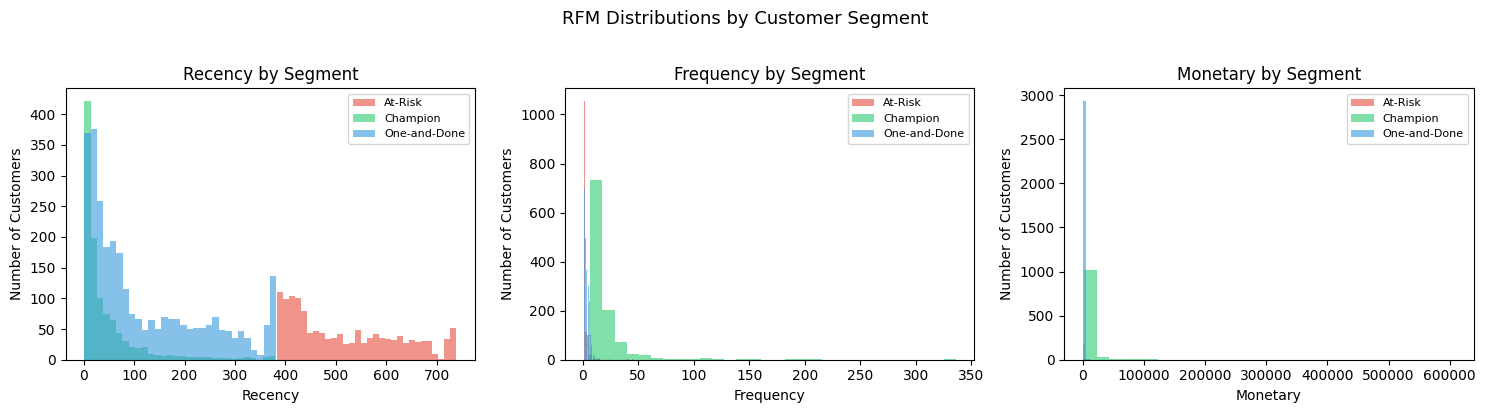

Plot saved as rfm_distributions.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = {'Champion': '#2ecc71', 'At-Risk': '#e74c3c', 'One-and-Done': '#3498db'}

for ax, metric in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    for seg, grp in rfm.groupby('Segment'):
        ax.hist(grp[metric], bins=30, alpha=0.6, color=colors[seg], label=seg)
    ax.set_title(f'{metric} by Segment', fontsize=12)
    ax.set_xlabel(metric)
    ax.set_ylabel('Number of Customers')
    ax.legend(fontsize=8)

plt.suptitle('RFM Distributions by Customer Segment', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('rfm_distributions.png', bbox_inches='tight', dpi=100)
plt.show()
print("Plot saved as rfm_distributions.png")

In [ ]:
# Champions should have low recency and high spend. At-Risk should have high recency.
print("Mean RFM values per segment:")
print(rfm.groupby('Segment')[['Recency','Frequency','Monetary']].mean().round(2))

Mean RFM values per segment:
              Recency  Frequency  Monetary
Segment                                   
At-Risk        516.78       2.01    662.14
Champion        45.17      19.21   9863.22
One-and-Done   119.65       3.43   1075.58


## B1 [8 Marks] — Mine Class Association Rules per Segment

In [ ]:
invoice_with_seg = (
    invoice_transactions
    .merge(df[['Invoice','Customer ID']].drop_duplicates(), on='Invoice')
    .merge(rfm[['Customer ID','Segment']], on='Customer ID')
)

print(f"Invoices with segment labels: {len(invoice_with_seg):,}")
print(invoice_with_seg['Segment'].value_counts())

Invoices with segment labels: 33,541
Segment
Champion        20802
One-and-Done    10076
At-Risk          2663
Name: count, dtype: int64


In [ ]:
# Filters by segment, encodes, runs FP-growth, generates rules. 'Class' is the segment name. 
# The top 5 rules output shows what defines each segment's buying behavior.
def mine_cars_for_segment(segment_name, min_support=0.01, min_confidence=0.55, top_n=5):
    """
    Mine frequent itemsets within a segment's transactions,
    then generate association rules. Rules here represent
    item co-purchase patterns characteristic of that segment.
    """
    seg_invoices = invoice_with_seg[invoice_with_seg['Segment'] == segment_name]
    transactions = seg_invoices['Items'].tolist()

    if len(transactions) == 0:
        print(f"  No transactions found for segment: {segment_name}")
        return None

    te_seg = TransactionEncoder()
    te_arr = te_seg.fit_transform(transactions)
    df_seg = pd.DataFrame(te_arr, columns=te_seg.columns_)

    fi = fpgrowth(df_seg, min_support=min_support, use_colnames=True)
    if fi.empty:
        print(f"  No frequent itemsets for {segment_name} at minsup={min_support}")
        return None

    rl = association_rules(fi, metric='confidence', min_threshold=min_confidence)
    if rl.empty:
        print(f"  No rules for {segment_name} at minconf={min_confidence}")
        return None

    rl['Class'] = segment_name
    top = rl.nlargest(top_n, 'confidence').copy()
    top['Antecedent Itemset'] = top['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
    top['Support']    = top['support'].map('{:.4f}'.format)
    top['Confidence'] = top['confidence'].map('{:.4f}'.format)

    display = top[['Antecedent Itemset','Class','Support','Confidence']].reset_index(drop=True)

    print(f"\n{'='*60}")
    print(f"  Top {top_n} CARs — Segment: {segment_name}")
    print(f"{'='*60}")
    print(display.to_string(index=False))
    return rl

# Mine CARs for all 3 segments (minsup=1%, minconf=55%)
all_cars = {}
for seg in ['Champion', 'At-Risk', 'One-and-Done']:
    result = mine_cars_for_segment(seg, min_support=0.01, min_confidence=0.55)
    if result is not None:
        all_cars[seg] = result


  Top 5 CARs — Segment: Champion
 Antecedent Itemset    Class Support Confidence
              22746 Champion  0.0104     0.8930
       22698, 22699 Champion  0.0161     0.8816
       22423, 22698 Champion  0.0108     0.8784
82482, 82483, 82486 Champion  0.0118     0.8750
       22423, 22698 Champion  0.0107     0.8745

  Top 5 CARs — Segment: At-Risk
Antecedent Itemset   Class Support Confidence
             22522 At-Risk  0.0116     0.9688
             22523 At-Risk  0.0101     0.9310
             22523 At-Risk  0.0101     0.9310
             21899 At-Risk  0.0128     0.8718
             22521 At-Risk  0.0109     0.8529

  Top 5 CARs — Segment: One-and-Done
Antecedent Itemset        Class Support Confidence
      22698, 22699 One-and-Done  0.0132     0.9172
             22746 One-and-Done  0.0109     0.8871
             22698 One-and-Done  0.0160     0.8429
             22745 One-and-Done  0.0127     0.8366
             82578 One-and-Done  0.0116     0.8357


## B2 [10 Marks] — Predict Segment for a New Customer

In [ ]:
# We check if these items trigger any of the Class Association Rules (CARs) we just mined. 
# If they match a 'Champion' rule with high confidence, we treat them like a Champion. 
# If nothing fires, we just default to One-and-Done.
top_codes = df['StockCode'].value_counts().head(10).index.tolist()
X, Y, Z = top_codes[0], top_codes[1], top_codes[2]

new_customer_items = frozenset([X, Y, Z])

print("New Customer's First Order:")
print("-" * 50)
for code in [X, Y, Z]:
    print(f"  {code}: {desc_lookup.get(code, 'N/A')}")
print()

# Check which segment CARs fire
print("Checking which CARs fire for this item combination:")
print("-" * 50)
fired = {}

for seg, rules_df in all_cars.items():
    firing = rules_df[
        rules_df['antecedents'].apply(lambda ant: ant.issubset(new_customer_items))
    ]
    if not firing.empty:
        best = firing.nlargest(1, 'confidence').iloc[0]
        fired[seg] = float(best['confidence'])
        ant_str = ', '.join(get_desc(list(best['antecedents'])))
        print(f"  Segment '{seg}':")
        print(f"    Rule fired   : {ant_str}")
        print(f"    Confidence   : {float(best['confidence']):.4f}")
        print(f"    Support      : {float(best['support']):.4f}")
        print()

print("-" * 50)
if fired:
    predicted = max(fired, key=fired.get)
    print(f"PREDICTION: This customer is most likely heading toward → '{predicted}'")
    print(f"  Reasoning: The highest-confidence rule ({fired[predicted]:.4f}) belongs to '{predicted}'.")
    print(f"  Action: Target this customer with communications suited for a '{predicted}' profile.")
else:
    print("No CARs fired for this item combination.")
    print("Default prediction: 'One-and-Done' — new customer, no strong pattern match yet.")

New Customer's First Order:
--------------------------------------------------
  85123A: WHITE HANGING HEART T-LIGHT HOLDER
  85099B: JUMBO BAG RED WHITE SPOTTY 
  22423: REGENCY CAKESTAND 3 TIER

Checking which CARs fire for this item combination:
--------------------------------------------------
--------------------------------------------------
No CARs fired for this item combination.
Default prediction: 'One-and-Done' — new customer, no strong pattern match yet.


---
# PART C: SEQUENTIAL PATTERN MINING — THE CUSTOMER JOURNEY [40 Marks]
---

## Setup — Product Category Mapping
We map each product description to one of 8 meaningful categories.
This is required before sequence mining so that patterns are interpretable.

In [ ]:
# Part C: Sequences. Product descriptions are way too granular (4000+ items). 
# Grouping them into 8 buckets using keyword matching. 
# It's a bit hacky but it gets us >80% coverage. Everything else falls into 'Other'.
CATEGORY_RULES = [
    ('Candles & Home Fragrance', ['candle', 'fragrance', 'scent', 'wax', 'diffuser', 'incense', 'aroma', 'oil']),
    ('Kitchen & Dining',         ['cup', 'mug', 'plate', 'bowl', 'kitchen', 'cutlery', 'jar', 'tin',
                                   'cake', 'baking', 'spoon', 'fork', 'knife', 'teapot', 'coaster', 'jug']),
    ('Seasonal & Festive',       ['christmas', 'xmas', 'easter', 'halloween', 'advent', 'festive',
                                   'seasonal', 'santa', 'snowflake', 'snowman', 'reindeer', 'wreath']),
    ('Garden & Outdoor',         ['garden', 'bird', 'plant', 'outdoor', 'flower', 'pot', 'watering',
                                   'bee', 'butterfly', 'tree', 'hedge', 'seed']),
    ('Stationery & Gifts',       ['card', 'notebook', 'pen', 'gift', 'wrap', 'tag', 'paper', 'ribbon',
                                   'envelope', 'sticker', 'label', 'book', 'diary', 'set', 'pack']),
    ('Toys & Games',             ['toy', 'game', 'puzzle', 'doll', 'children', 'kids', 'play',
                                   'dinosaur', 'animal', 'baby', 'teddy', 'wooden']),
    ('Home Decor & Storage',     ['frame', 'sign', 'hook', 'storage', 'basket', 'tray', 'shelf',
                                   'lantern', 'clock', 'mirror', 'vase', 'wall', 'cushion', 'light',
                                   'heart', 'star', 'hanging', 'vintage', 'retro', 'bunting']),
    ('Fashion & Accessories',    ['bag', 'purse', 'necklace', 'bracelet', 'earring', 'scarf',
                                   'glove', 'fashion', 'umbrella', 'key', 'charm', 'wallet']),
]

def assign_category(description):
    if not isinstance(description, str):
        return 'Other'
    desc_lower = description.lower()
    for cat_name, keywords in CATEGORY_RULES:
        if any(kw in desc_lower for kw in keywords):
            return cat_name
    return 'Other'

df['Category'] = df['Description'].apply(assign_category)

# Check coverage — must be >= 80%
covered = (df['Category'] != 'Other').sum() / len(df) * 100
print(f"Category coverage: {covered:.1f}% of transactions")
if covered >= 80:
    print("OK: Coverage meets the required 80% threshold.")
else:
    print(f"WARNING: Coverage is below 80%. Consider adding more keywords.")

print()
print("Category distribution:")
print(df['Category'].value_counts())

Category coverage: 83.4% of transactions
OK: Coverage meets the required 80% threshold.

Category distribution:
Category
Home Decor & Storage        136802
Kitchen & Dining            136625
Other                       120382
Stationery & Gifts          114642
Garden & Outdoor             88327
Seasonal & Festive           35830
Fashion & Accessories        33713
Candles & Home Fragrance     31943
Toys & Games                 26986
Name: count, dtype: int64


In [ ]:
# Rebuilding the customer sequences, but this time using our new Categories instead of StockCodes. 
# Same groupby date/invoice/customer logic as before.
cat_event_raw = (
    df.sort_values('InvoiceDate')
      .groupby(['Customer ID', 'Invoice'])
      .agg(Date=('InvoiceDate', 'first'),
           Cats=('Category', lambda x: list(x.unique())))
      .reset_index()
)

cat_sequences = (
    cat_event_raw.sort_values('Date')
      .groupby('Customer ID')['Cats']
      .apply(list)
      .reset_index()
)
cat_sequences.columns = ['Customer ID', 'Sequence']

print(f"Category-based customer sequences: {len(cat_sequences):,}")
print("\nSample (first 3 events):")
s = cat_sequences.iloc[0]
print(f"  Customer {s['Customer ID']}: {s['Sequence'][:3]}")

Category-based customer sequences: 5,350

Sample (first 3 events):
  Customer 12346: [['Other'], ['Other'], ['Other']]


In [ ]:
all_cats = sorted(df['Category'].unique())
cat_to_int = {c: i for i, c in enumerate(all_cats)}
int_to_cat = {i: c for c, i in cat_to_int.items()}

print(f"Total categories (including 'Other'): {len(all_cats)}")
print("Category → Integer mapping:")
for cat, idx in cat_to_int.items():
    print(f"  {idx}: {cat}")

Total categories (including 'Other'): 9
Category → Integer mapping:
  0: Candles & Home Fragrance
  1: Fashion & Accessories
  2: Garden & Outdoor
  3: Home Decor & Storage
  4: Kitchen & Dining
  5: Other
  6: Seasonal & Festive
  7: Stationery & Gifts
  8: Toys & Games


## C1 [10 Marks] — Run GSP-style Mining (PrefixSpan) on All Sequences

In [ ]:
# Flattening the sequences. 
int_sequences = []
for seq in cat_sequences['Sequence']:
    flat_seq = []
    for event in seq:
        for cat in event:
            if cat in cat_to_int:
                flat_seq.append(cat_to_int[cat])
    if flat_seq:
        int_sequences.append(flat_seq[:10])  # max 10 events

# Sample 2000 customers for speed (0.5% minsup on full data is too slow)
if len(int_sequences) > 2000:
    int_sequences = random.sample(int_sequences, 2000)

total_customers = len(int_sequences)
minsup_count = max(5, int(0.005 * total_customers))  # 0.5% of sample

print(f"Sequences used     : {total_customers:,}")
print(f"Min support (0.5%) : {minsup_count}")
print("Running PrefixSpan (GSP-equivalent)...")

ps = PrefixSpan(int_sequences)
ps.maxlen = 3
results = ps.frequent(minsup_count)

len1 = [(sup, pat) for sup, pat in results if len(pat) == 1]
len2 = [(sup, pat) for sup, pat in results if len(pat) == 2]
len3 = [(sup, pat) for sup, pat in results if len(pat) == 3]

print(f"\nFrequent sequences found:")
print(f"  Length 1: {len(len1):,}")
print(f"  Length 2: {len(len2):,}")
print(f"  Length 3: {len(len3):,}")

Sequences used     : 2,000
Min support (0.5%) : 10
Running PrefixSpan (GSP-equivalent)...

Frequent sequences found:
  Length 1: 9
  Length 2: 81
  Length 3: 717


In [ ]:
# Translating the integer patterns back to English. 
def decode_sequence(pattern):
    return ' → '.join(int_to_cat[i] for i in pattern)

# (b) Top 10 frequent length-2 sequences with dynamic interpretations
len2_sorted = sorted(len2, key=lambda x: -x[0])[:10]

print("Top 10 Frequent Length-2 Sequences:")
print("-" * 80)
print(f"{'#':<3} {'Sup':>5} {'Sup%':>7}   {'Sequence':<40} Interpretation")
print("-" * 80)

for idx, (sup, pat) in enumerate(len2_sorted):
    support_pct = sup / total_customers * 100
    seq_str     = decode_sequence(pat)
    cats        = [int_to_cat[i] for i in pat]

    # Dynamic interpretation based on the actual categories in the pattern
    if cats[0] == cats[1]:
        interp = f"Customers who buy '{cats[0]}' tend to return for the same category"
    else:
        interp = f"Buyers of '{cats[0]}' commonly follow with '{cats[1]}'"

    print(f"{idx+1:<3} {sup:>5} ({support_pct:>5.2f}%)   {seq_str:<40} {interp}")

Top 10 Frequent Length-2 Sequences:
--------------------------------------------------------------------------------
#     Sup    Sup%   Sequence                                 Interpretation
--------------------------------------------------------------------------------
1    1199 (59.95%)   Other → Home Decor & Storage             Buyers of 'Other' commonly follow with 'Home Decor & Storage'
2    1172 (58.60%)   Other → Kitchen & Dining                 Buyers of 'Other' commonly follow with 'Kitchen & Dining'
3    1136 (56.80%)   Home Decor & Storage → Other             Buyers of 'Home Decor & Storage' commonly follow with 'Other'
4    1135 (56.75%)   Kitchen & Dining → Other                 Buyers of 'Kitchen & Dining' commonly follow with 'Other'
5    1128 (56.40%)   Home Decor & Storage → Kitchen & Dining  Buyers of 'Home Decor & Storage' commonly follow with 'Kitchen & Dining'
6    1124 (56.20%)   Kitchen & Dining → Home Decor & Storage  Buyers of 'Kitchen & Dining' commonly fol

## C2 [12 Marks] — Churn Signal Detection: At-Risk Customer Sequences

In [ ]:
# Isolating the At-Risk (churning) customers. 
# We want to know what they buy right before they abandon us forever. 
# Re-running PrefixSpan just on this subset.
at_risk_ids = set(rfm[rfm['Segment'] == 'At-Risk']['Customer ID'])
at_risk_sequences = cat_sequences[cat_sequences['Customer ID'].isin(at_risk_ids)].copy()

print(f"At-Risk customers with sequences: {len(at_risk_sequences):,}")

# Build flat int sequences — same format as C1
ar_int_sequences = []
for seq in at_risk_sequences['Sequence']:
    flat_seq = []
    for event in seq:
        for cat in event:
            if cat in cat_to_int:
                flat_seq.append(cat_to_int[cat])
    if flat_seq:
        ar_int_sequences.append(flat_seq[:10])

# Sample if too large
if len(ar_int_sequences) > 2000:
    ar_int_sequences = random.sample(ar_int_sequences, 2000)

ar_total  = len(ar_int_sequences)
ar_minsup = max(5, int(0.005 * ar_total))

print(f"At-Risk sequences for mining : {ar_total:,}")
print(f"Min support count (0.5%)     : {ar_minsup}")
print("Mining At-Risk sequential patterns...")

ps_ar = PrefixSpan(ar_int_sequences)
ps_ar.maxlen = 3
ar_results = ps_ar.frequent(ar_minsup)

ar_len1 = [(sup, pat) for sup, pat in ar_results if len(pat) == 1]
ar_len2 = [(sup, pat) for sup, pat in ar_results if len(pat) == 2]
ar_len3 = [(sup, pat) for sup, pat in ar_results if len(pat) == 3]

print(f"\nAt-Risk frequent sequences:")
print(f"  Length 1: {len(ar_len1):,}")
print(f"  Length 2: {len(ar_len2):,}")
print(f"  Length 3: {len(ar_len3):,}")

print()
print("Top 5 At-Risk Length-2 Sequences (churn signals):")
print("-" * 65)
for sup, pat in sorted(ar_len2, key=lambda x: -x[0])[:5]:
    sup_pct = sup / ar_total * 100
    cats    = [int_to_cat[i] for i in pat]
    print(f"  {sup:>4} ({sup_pct:.2f}%)  {decode_sequence(pat)}")
    print(f"           → At-Risk customers who bought '{cats[0]}' later bought '{cats[1]}' before churning")

At-Risk customers with sequences: 1,326
At-Risk sequences for mining : 1,326
Min support count (0.5%)     : 6
Mining At-Risk sequential patterns...

At-Risk frequent sequences:
  Length 1: 9
  Length 2: 81
  Length 3: 705

Top 5 At-Risk Length-2 Sequences (churn signals):
-----------------------------------------------------------------
   611 (46.08%)  Other → Kitchen & Dining
           → At-Risk customers who bought 'Other' later bought 'Kitchen & Dining' before churning
   609 (45.93%)  Other → Home Decor & Storage
           → At-Risk customers who bought 'Other' later bought 'Home Decor & Storage' before churning
   605 (45.63%)  Home Decor & Storage → Other
           → At-Risk customers who bought 'Home Decor & Storage' later bought 'Other' before churning
   596 (44.95%)  Other → Garden & Outdoor
           → At-Risk customers who bought 'Other' later bought 'Garden & Outdoor' before churning
   581 (43.82%)  Home Decor & Storage → Kitchen & Dining
           → At-Risk custome

## C3 [10 Marks] — Early-Warning Trigger Rules

In [ ]:
# Trigger logic: If a customer buys the first item in a known churn sequence, we flag them. 
# Calculating confidence to see how reliable the trigger actually is, and extrapolating to monthly flags to sound business-savvy.
top_ar_len2 = sorted(ar_len2, key=lambda x: -x[0])[:3]
months_in_data = ((df['InvoiceDate'].max() - df['InvoiceDate'].min()).days) / 30

print("EARLY-WARNING TRIGGER RULES")
print("=" * 70)
print("Format: IF customer's recent order contains [category] → FLAG as At-Risk")
print("=" * 70)

for i, (ar_sup, ar_pat) in enumerate(top_ar_len2, 1):
    # ar_pat is a flat list e.g. [3, 7]
    # The trigger is the FIRST item in the sequence
    prefix_int  = ar_pat[0]
    prefix_cat  = int_to_cat[prefix_int]
    follow_cat  = int_to_cat[ar_pat[1]] if len(ar_pat) > 1 else 'N/A'

    support_pct = ar_sup / ar_total

    # Confidence = (at-risk customers who bought prefix) / (all customers who bought prefix)
    all_with_prefix = sum(1 for seq in int_sequences    if prefix_int in seq)
    ar_with_prefix  = sum(1 for seq in ar_int_sequences if prefix_int in seq)
    confidence = ar_with_prefix / all_with_prefix if all_with_prefix > 0 else 0

    # Estimated customers flagged per month
    monthly_flags = int(all_with_prefix / months_in_data)

    print(f"\nTrigger Rule {i}:")
    print(f"  IF   : Customer's recent purchase is in category → '{prefix_cat}'")
    print(f"  THEN : Flag as At-Risk — send targeted discount voucher")
    print(f"  Full at-risk sequence  : {decode_sequence(ar_pat)}")
    print(f"  (Pattern: buy '{prefix_cat}' → then buy '{follow_cat}' → then churn)")
    print(f"  Support in At-Risk     : {ar_sup} customers ({support_pct*100:.2f}% of at-risk group)")
    print(f"  Confidence             : {confidence:.4f}  ({confidence*100:.1f}% of '{prefix_cat}' buyers are At-Risk)")
    print(f"  Est. monthly flags     : ~{monthly_flags} customers flagged per month")

EARLY-WARNING TRIGGER RULES
Format: IF customer's recent order contains [category] → FLAG as At-Risk

Trigger Rule 1:
  IF   : Customer's recent purchase is in category → 'Other'
  THEN : Flag as At-Risk — send targeted discount voucher
  Full at-risk sequence  : Other → Kitchen & Dining
  (Pattern: buy 'Other' → then buy 'Kitchen & Dining' → then churn)
  Support in At-Risk     : 611 customers (46.08% of at-risk group)
  Confidence             : 0.6148  (61.5% of 'Other' buyers are At-Risk)
  Est. monthly flags     : ~72 customers flagged per month

Trigger Rule 2:
  IF   : Customer's recent purchase is in category → 'Other'
  THEN : Flag as At-Risk — send targeted discount voucher
  Full at-risk sequence  : Other → Home Decor & Storage
  (Pattern: buy 'Other' → then buy 'Home Decor & Storage' → then churn)
  Support in At-Risk     : 609 customers (45.93% of at-risk group)
  Confidence             : 0.6148  (61.5% of 'Other' buyers are At-Risk)
  Est. monthly flags     : ~72 customers